# Example 4: Si and GaAs diode prediction

This notebook propagates the example equilibrium, mobility, lifetime, and geometry inputs into finite-base saturation current, ideal J–V response, stored charge, and diffusion capacitance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import elementary_charge as q, Boltzmann as k_B, epsilon_0

ROOT = Path.cwd()
while not (ROOT / "notebooks" / "la2_models.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the LA2 workspace")
    ROOT = ROOT.parent
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
from la2_models import SILICON,GAAS,intrinsic_concentration_m3,mobility_m2_Vs,diffusivity_m2_s

T=300.0; NA=1e23; ND=1e22
controls=[]
for material in (SILICON,GAAS):
    ni=float(intrinsic_concentration_m3(material,T))
    Dn=float(diffusivity_m2_s(mobility_m2_Vs(material,NA,"electron"),T))
    Dp=float(diffusivity_m2_s(mobility_m2_Vs(material,ND,"hole"),T))
    Ln=np.sqrt(Dn*material.electron_lifetime_s); Lp=np.sqrt(Dp*material.hole_lifetime_s)
    wp=4*Ln; wn=4*Lp
    npo=ni**2/NA; pno=ni**2/ND
    Js_direct=q*(Dn*npo/Ln/np.tanh(wp/Ln)+Dp*pno/Lp/np.tanh(wn/Lp))
    controls.append((material,ni,Dn,Dp,Ln,Lp,wp,wn,npo,pno,Js_direct))
    print(material.name,f"Js={Js_direct:.3e} A/m^2, Ln={Ln*1e6:.2f} µm, Lp={Lp*1e6:.2f} µm")

Si Js=7.142e-09 A/m^2, Ln=137.10 µm, Lp=105.34 µm
GaAs Js=8.791e-14 A/m^2, Ln=3.47 µm, Lp=0.97 µm


In [2]:
from la2_models import finite_base_saturation_current_A_m2,ideal_diode_current_A_m2

results=[]
for item in controls:
    material,ni,Dn,Dp,Ln,Lp,wp,wn,npo,pno,Js_direct=item
    Js=finite_base_saturation_current_A_m2(ni,NA,ND,Dn,Dp,material.electron_lifetime_s,material.hole_lifetime_s,wp,wn)
    assert abs(Js-Js_direct)/Js<1e-13
    vmax=0.85 if material.name=="Si" else 1.30
    voltage=np.linspace(-0.2,vmax,500)
    current=ideal_diode_current_A_m2(voltage,Js,T)
    VT=k_B*T/q
    hole_boundary=pno*np.expm1(np.clip(voltage/VT,-100,100))
    stored=q*Lp*hole_boundary
    diffusion_capacitance=stored/VT
    results.append((material,voltage,current,stored,diffusion_capacitance,Js))

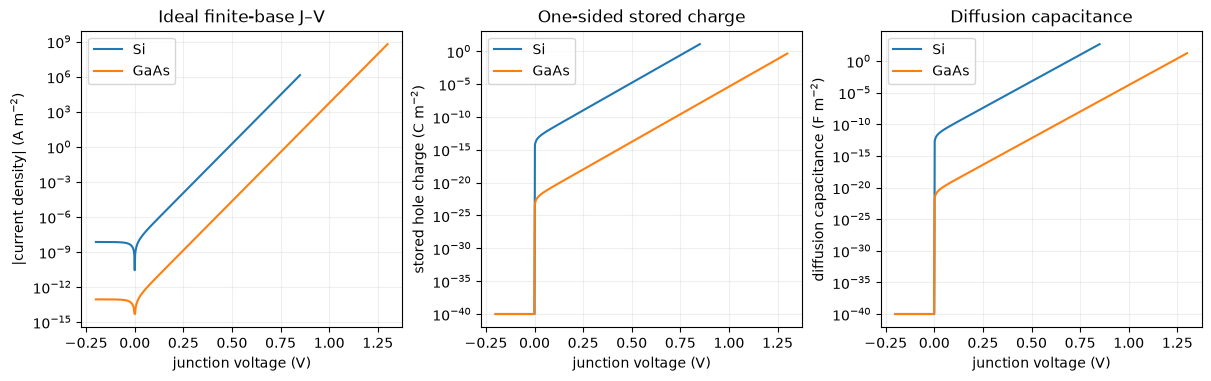

In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,3.7),layout="constrained")
for material,voltage,current,stored,Cd,Js in results:
    axes[0].semilogy(voltage,np.maximum(np.abs(current),1e-40),label=material.name)
    axes[1].semilogy(voltage,np.maximum(stored,1e-40),label=material.name)
    axes[2].semilogy(voltage,np.maximum(Cd,1e-40),label=material.name)
axes[0].set(xlabel="junction voltage (V)",ylabel="|current density| (A m$^{-2}$)",title="Ideal finite-base J–V")
axes[1].set(xlabel="junction voltage (V)",ylabel="stored hole charge (C m$^{-2}$)",title="One-sided stored charge")
axes[2].set(xlabel="junction voltage (V)",ylabel="diffusion capacitance (F m$^{-2}$)",title="Diffusion capacitance")
for ax in axes: ax.grid(alpha=.2,which="both"); ax.legend()
fig.savefig(FIGURES/'example-si-gaas-diode-prediction.pdf',metadata={'CreationDate':None,'ModDate':None})
plt.show()

In [4]:
# The material comparison is a chain-of-inputs comparison, not a universal ranking.
for material,voltage,current,stored,Cd,Js in results:
    target=1e4
    forward=np.interp(np.log(target),np.log(np.maximum(current[voltage>0],1e-300)),voltage[voltage>0])
    print(material.name,f"ideal voltage near J={target:.0e} A/m^2: {forward:.3f} V")
print("GaAs has a much smaller ideal Js here because its example ni is much smaller; real leakage may be defect- or surface-controlled.")
print("wrote figures/example-si-gaas-diode-prediction.pdf")

Si ideal voltage near J=1e+04 A/m^2: 0.723 V
GaAs ideal voltage near J=1e+04 A/m^2: 1.015 V
GaAs has a much smaller ideal Js here because its example ni is much smaller; real leakage may be defect- or surface-controlled.
wrote figures/example-si-gaas-diode-prediction.pdf
